# UTS — Soal Praktik (120 menit, 40 poin)
**Mata Kuliah Sistem Cerdas (TI24317) — Politeknik Negeri Madiun**

| | Isi dengan datamu |
|---|---|
| **Nama** | Robbin Chandra Falla Arya Ardhana |
| **NIM** | 253307059 |
| **Kelas** | 3B |

## Aturan
- **Open modul**: boleh membuka modul & notebook milik sendiri
- **Dilarang**: berkomunikasi, memakai AI, berbagi file
- Pastikan **kos_madiun.csv** satu folder dengan notebook ini
- Sebelum mengumpulkan: **Kernel → Restart & Run All** wajib tanpa error
- Kumpulkan sebagai **UTS_NIM_Nama.ipynb**

---
## Soal U1 — Analisis Data Kos (15 poin)
1. Muat `kos_madiun.csv`, tampilkan 5 baris pertama dan `info()`
2. Buat kolom `skor` = rating × 20 − harga / 50 − jarak_km × 5
3. Tampilkan `nama, harga, jarak_km, rating, skor` untuk **5 kos skor tertinggi**
4. Tampilkan **rata-rata harga** kos ber-AC vs tidak (groupby), lalu buat **histogram harga** (judul + label sumbu)

,nama,jarak_km,harga,ac,rating
0,Kos Melati,1.8,600,tidak,4.3
1,Kos Mawar,0.6,1250,ya,3.7
2,Kos Anggrek,0.6,1200,ya,3.1
3,Kos Kenanga,2.3,500,ya,3.2
4,Kos Dahlia,2.3,1300,ya,4.9


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   nama      30 non-null     str    
 1   jarak_km  30 non-null     float64
 2   harga     30 non-null     int64  
 3   ac        30 non-null     str    
 4   rating    30 non-null     float64
dtypes: float64(2), int64(1), str(2)
memory usage: 1.3 KB


,nama,harga,jarak_km,rating,skor
1,Kos Seruni,650,1.5,4.6,71.5
2,Kos Barokah,850,1.3,4.5,66.5
3,Kos Griya,800,2.2,4.6,65.0
4,Kos Melati,600,1.8,4.3,65.0
5,Kos Dahlia,1300,2.3,4.9,60.5


,harga
ac,
tidak,1046.875000
ya,1067.857143


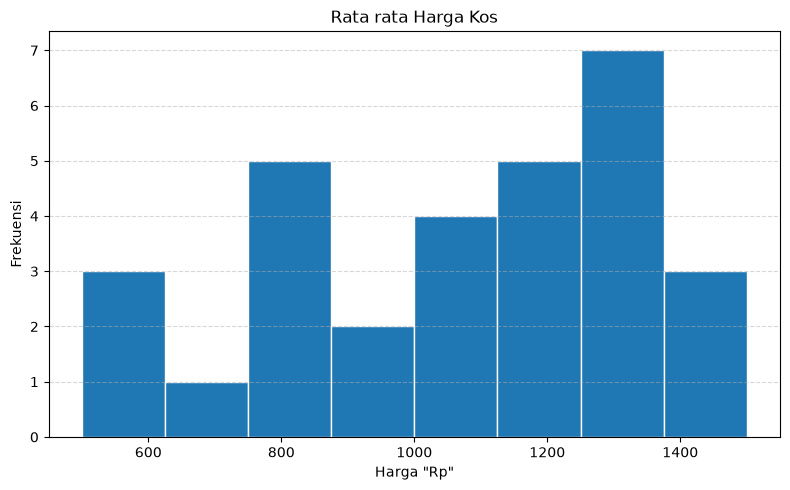

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Muat dataset, tampilkan 5 baris pertama dan info()
data = 'https://raw.githubusercontent.com/cpzz18/Matkul-sistem-cerdas/refs/heads/main/Minggu%204/kos_madiun.csv'
df = pd.read_csv(data)
display(df.head())
df.info()

# 2. Buat kolom skor = rating × 20 − harga / 50 − jarak_km × 5
df['skor'] = df['rating'] * 20 - df['harga'] / 50 - df['jarak_km'] * 5

# 3. Tampilkan nama, harga, jarak_km, rating, skor untuk 5 kos skor tertinggi
t5 = df[['nama', 'harga', 'jarak_km', 'rating', 'skor']].sort_values(by='skor', ascending=False).head(5).reset_index(drop=True)
t5.index += 1
display(top5)

# 4. Tampilkan rata-rata harga kos ber-AC vs tidak (groupby), lalu buat histogram harga (judul + label sumbu)
rataharga_ac = df.groupby('ac')[['harga']].mean()
display(rataharga_ac)

plt.figure(figsize=(8, 5))
plt.hist(df['harga'], bins=8, edgecolor='white')
plt.title('Rata rata Harga Kos')
plt.xlabel('Harga "Rp"')
plt.ylabel('Frekuensi')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


---
## Soal U2 — Sistem Pakar Diagnosa WiFi (12 poin)
Aturan dan dua kasus fakta **sudah disediakan — jangan diubah**.
Tulis fungsi **forward chaining**, jalankan untuk **kedua kasus**,
cetak **jejak aturan terpicu** dan **diagnosa akhir** masing-masing.

In [22]:
# Basis pengetahuan -- JANGAN DIUBAH
aturan_wifi = [
    {"jika": ["internet mati", "terjadi di semua perangkat"],
     "maka": "masalah dari ISP/router"},
    {"jika": ["masalah dari ISP/router", "lampu indikator router mati"],
     "maka": "DIAGNOSA: router/adaptor mati total, cek listrik & adaptor"},
    {"jika": ["masalah dari ISP/router", "lampu indikator router normal"],
     "maka": "DIAGNOSA: gangguan dari ISP, hubungi layanan pelanggan"},
    {"jika": ["internet mati", "hanya di laptop saya"],
     "maka": "masalah di perangkat"},
    {"jika": ["masalah di perangkat", "wifi tersambung tapi internet tidak ada"],
     "maka": "DIAGNOSA: konfigurasi IP/DNS bermasalah, lakukan reset network"},
]

# Dua kasus uji -- JANGAN DIUBAH
kasus_A = ["internet mati", "terjadi di semua perangkat", "lampu indikator router normal"]
kasus_B = ["internet mati", "hanya di laptop saya", "wifi tersambung tapi internet tidak ada"]

# ========== JAWABAN U2 ==========
# tulis fungsi forward chaining + pengujian kedua kasus di bawah baris ini:
def forward_chaining(aturan, fakta_awal):
    fakta = list(fakta_awal)
    ada_baru = True

    while ada_baru:
        ada_baru = False
        for r in aturan:
            terpenuhi = all(k in fakta for k in r["jika"])
            if terpenuhi and r["maka"] not in fakta:
                fakta.append(r["maka"])
                print(f"  Terpicu: {r['jika']} -> {r['maka']}")
                ada_baru = True
    return fakta

# 1. Kasus A
print("--Pengujian Kasus A")
hasil_A = forward_chaining(aturan_wifi, kasus_A)
diagnosa_A = [f for f in hasil_A if f.startswith("DIAGNOSA")]
for d in diagnosa_A:
    print("Diagnosa akhir:", d)
print()

# 2. Kasus B
print("--Hasil Kasus B")
hasil_B = forward_chaining(aturan_wifi, kasus_B)
diagnosa_B = [f for f in hasil_B if f.startswith("DIAGNOSA")]
for d in diagnosa_B:
    print("Diagnosa akhir:", d)

--Pengujian Kasus A
  Terpicu: ['internet mati', 'terjadi di semua perangkat'] -> masalah dari ISP/router
  Terpicu: ['masalah dari ISP/router', 'lampu indikator router normal'] -> DIAGNOSA: gangguan dari ISP, hubungi layanan pelanggan
Diagnosa akhir: DIAGNOSA: gangguan dari ISP, hubungi layanan pelanggan

--Hasil Kasus B
  Terpicu: ['internet mati', 'hanya di laptop saya'] -> masalah di perangkat
  Terpicu: ['masalah di perangkat', 'wifi tersambung tapi internet tidak ada'] -> DIAGNOSA: konfigurasi IP/DNS bermasalah, lakukan reset network
Diagnosa akhir: DIAGNOSA: konfigurasi IP/DNS bermasalah, lakukan reset network


---
## Soal U3 — Fuzzy Kategori Harga Kos (13 poin)
1. Tulis fungsi `segitiga(x, a, b, c)`
2. Hitung derajat keanggotaan **harga 750 (ribu rupiah)** pada:
   - murah (0, 400, 800)
   - sedang (500, 900, 1300)
   - mahal (1000, 1400, 1800)
3. Tulis **interpretasinya** di sel markdown di bawah

In [23]:
# ========== JAWABAN U3 ==========
# tulis kodemu di bawah baris ini:

# 1. Tulis fungsi segitiga(x, a, b, c)
def segitiga(x, a, b, c):
    """Derajat keanggotaan fungsi segitiga (a, b, c)."""
    if x <= a or x >= c:
        return 0.0 
    if x <= b:
        return (x - a) / (b - a)  
    return (c - x) / (c - b)  

# 2. Hitung derajat keanggotaan harga 750 (ribu rupiah)
harga = 750

murah = segitiga(harga, 0, 400, 800)
sedang = segitiga(harga, 500, 900, 1300)
mahal = segitiga(harga, 1000, 1400, 1800)

print(f"Harga : Rp{harga}.000")
print(f"murah  (0, 400, 800)     : {murah}")
print(f"sedang (500, 900, 1300)  : {sedang}")
print(f"mahal  (1000, 1400, 1800): {mahal}")

Harga : Rp750.000
murah  (0, 400, 800)     : 0.125
sedang (500, 900, 1300)  : 0.625
mahal  (1000, 1400, 1800): 0.0


**Interpretasi U3**

Perhitungan fungsi keanggotaan fuzzy segitiga dengan harga 750.000
1. Derajat keanggotaan kategori sedang adalah 0.625 (62.5%), yang merupakan nilai tertinggi/dominan.
2. Derajat keanggotaan kategori murah adalah 0.125 (12.5%), menunjukkan harga ini berada di masa transisi keluar dari batas atas kategori murah sisi turun segitiga murah
3. Derajat keanggotaan kategori mahal adalah 0.0 (0.0%), artinya harga Rp750.000 sama sekali belum masuk rentang kategori mahal berada di luar batas segitiga mahal

**Kesimpulan:** Kos dengan harga Rp750.000 paling dominan diklasifikasikan ke dalam kategori **harga sedang**.


---
## Checklist sebelum mengumpulkan
- [✓] Restart & Run All tanpa error
- [✓] U1: skor, top-5, groupby, histogram berlabel
- [✓] U2: jejak aturan + diagnosa kasus A dan B
- [✓] U3: tiga derajat keanggotaan + interpretasi
- [✓ ] Rename **UTS_NIM_Nama.ipynb** dan unggah ke LMS

*Selamat mengerjakan — teliti lebih berharga daripada cepat.*